In [150]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures,OneHotEncoder
from sklearn.metrics import mean_absolute_error
from scipy.special import expit,softmax # expit : 이진분류함수 , softmax : 다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV


In [151]:
# LinearRegression
df = pd.read_csv('data/picher_stats_2017.csv')
df.head()
# df.info()
# df.shape #(152, 22)
# df.describe()

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000
2,양현종,KIA,20,6,0,0,0,31,31,193.1,...,0.79,0.332,72.1,3.44,6.54,3.94,3.82,5.64,230000,150000
3,차우찬,LG,10,7,0,0,0,28,28,175.2,...,1.02,0.298,75.0,3.43,6.11,4.20,4.03,4.63,100000,100000
4,레일리,롯데,13,7,0,0,0,30,30,187.1,...,0.91,0.323,74.1,3.80,6.13,4.36,4.31,4.38,111000,85000


In [152]:
df.columns

Index(['선수명', '팀명', '승', '패', '세', '홀드', '블론', '경기', '선발', '이닝', '삼진/9',
       '볼넷/9', '홈런/9', 'BABIP', 'LOB%', 'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR',
       '연봉(2018)', '연봉(2017)'],
      dtype='str')

In [153]:
data = df[['승', '패', '세', '홀드', '블론', '경기', '선발', '이닝', '삼진/9','볼넷/9', '홈런/9', 'BABIP', 'LOB%', 'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR','연봉(2017)']].values
label = df[['연봉(2018)']].values
label[:2]

array([[140000],
       [120000]])

In [154]:
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42,test_size=0.2)

In [155]:
# poly = PolynomialFeatures(degree=1,include_bias=False)
# poly.fit(train_data)
# train_poly = poly.transform(train_data)
# test_poly = poly.transform(test_data)

In [156]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [157]:
param = {
    'alpha':[0.001,0.01,0.1,0,1,10,100,100]
}

In [158]:

gs = GridSearchCV(Ridge(random_state=42),param,return_train_score=True,n_jobs=-1)
gs.fit(train_scaled,train_label)
ridge = gs.best_estimator_
print("train 정확도 ",ridge.score(train_scaled,train_label))
print("test 정확도 ",ridge.score(test_scaled,test_label))

print('가장좋은 파라미터값 : ',gs.best_params_)
print(gs.cv_results_['mean_test_score'])
print(gs.cv_results_['mean_train_score'])

# train 정확도  0.9172010716207588
# test 정확도  0.875529936253929
# 가장좋은 파라미터값 :  {'alpha': 10}
# [0.83778083 0.84189925 0.84516996 0.83605091 0.85322208 0.86514538
#  0.76561309 0.76561309]
# [0.92917984 0.92897912 0.92877211 0.92919628 0.92812281 0.91809501
#  0.79667895 0.79667895]

# lr = LinearRegression()
# lr.fit(train_scaled,train_label)
# predict = lr.predict(test_scaled)
# print("train 정확도 ",lr.score(train_scaled,train_label))
# print("test 정확도 ",lr.score(test_scaled,test_label))



train 정확도  0.9172010716207588
test 정확도  0.875529936253929
가장좋은 파라미터값 :  {'alpha': 10}
[0.83778083 0.84189925 0.84516996 0.83605091 0.85322208 0.86514538
 0.76561309 0.76561309]
[0.92917984 0.92897912 0.92877211 0.92919628 0.92812281 0.91809501
 0.79667895 0.79667895]


In [159]:
predict = ridge.predict(test_data)

In [160]:
df.columns


Index(['선수명', '팀명', '승', '패', '세', '홀드', '블론', '경기', '선발', '이닝', '삼진/9',
       '볼넷/9', '홈런/9', 'BABIP', 'LOB%', 'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR',
       '연봉(2018)', '연봉(2017)'],
      dtype='str')

In [161]:
# pip install statsmodels
# 회귀분석 통계결과표 : P>|t| 통계량의 절대값보다 크거나 같은 값이 나올 확률
import statsmodels.api as sm

train_scaled = sm.add_constant(train_scaled)
model = sm.OLS(train_label,train_scaled).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.924
Model:                            OLS   Adj. R-squared:                  0.910
Method:                 Least Squares   F-statistic:                     64.82
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           7.33e-48
Time:                        18:00:28   Log-Likelihood:                -1275.4
No. Observations:                 121   AIC:                             2591.
Df Residuals:                     101   BIC:                             2647.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.994e+04    910.214     21.910      0.000    1.81e+04    2.17e+04
x1          4395.5745   2832.591      1.552      0.124   -1223.523       1e+04
x2          -181.0170   2115.039     -0.086      0.932   -4376.685    4014.651
x3          -234.6394   1433.605     -0.164      0.870   -3078.526    2609.247
x4          -795.8327   1600.092     -0.497      0.620   -3969.984    2378.319
x5          1065.2349   1426.553      0.747      0.457   -1764.663    3895.133
x6         -3422.0279   3647.550     -0.938      0.350   -1.07e+04    3813.730
x7         -8453.0994   6349.147     -1.331      0.186    -2.1e+04    4141.901
x8          4745.0565   7900.707      0.601      0.549   -1.09e+04    2.04e+04
x9          -418.3394   6628.438     -0.063      0.950   -1.36e+04    1.27e+04
x10         4632.3840   6396.429      0.724      0.471   -8056.411    1.73e+04
x11         9142.2129   1.68e+04      0.545      0.587   -2.42e+04    4.24e+04
x12        -1426.0658   1508.920     -0.945      0.347   -4419.358    1567.226
x13         -608.9750   1772.873     -0.343      0.732   -4125.877    2907.928
x14          306.5617   2782.269      0.110      0.912   -5212.711    5825.835
x15         -659.3270   3311.941     -0.199      0.843   -7229.328    5910.674
x16        -3.685e+04   9.94e+04     -0.371      0.711   -2.34e+05     1.6e+05
x17         2.787e+04   8.29e+04      0.336      0.737   -1.37e+05    1.92e+05
x18         1.253e+04   2977.444      4.207      0.000    6618.758    1.84e+04
x19         2.285e+04   1347.093     16.960      0.000    2.02e+04    2.55e+04
==============================================================================
Omnibus:                       32.192   Durbin-Watson:                   1.801
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              432.406
Skew:                           0.029   Prob(JB):                     1.27e-94
Kurtosis:                      12.261   Cond. No.                         377.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

[Text(0, 0, 'const'),
 Text(1, 0, '승'),
 Text(2, 0, '패'),
 Text(3, 0, '세'),
 Text(4, 0, '홀드'),
 Text(5, 0, '블론'),
 Text(6, 0, '경기'),
 Text(7, 0, '선발'),
 Text(8, 0, '이닝'),
 Text(9, 0, '삼진/9'),
 Text(10, 0, '볼넷/9'),
 Text(11, 0, '홈런/9'),
 Text(12, 0, 'BABIP'),
 Text(13, 0, 'LOB%'),
 Text(14, 0, 'ERA'),
 Text(15, 0, 'RA9-WAR'),
 Text(16, 0, 'FIP'),
 Text(17, 0, 'kFIP'),
 Text(18, 0, 'WAR'),
 Text(19, 0, '연봉(2017)')]

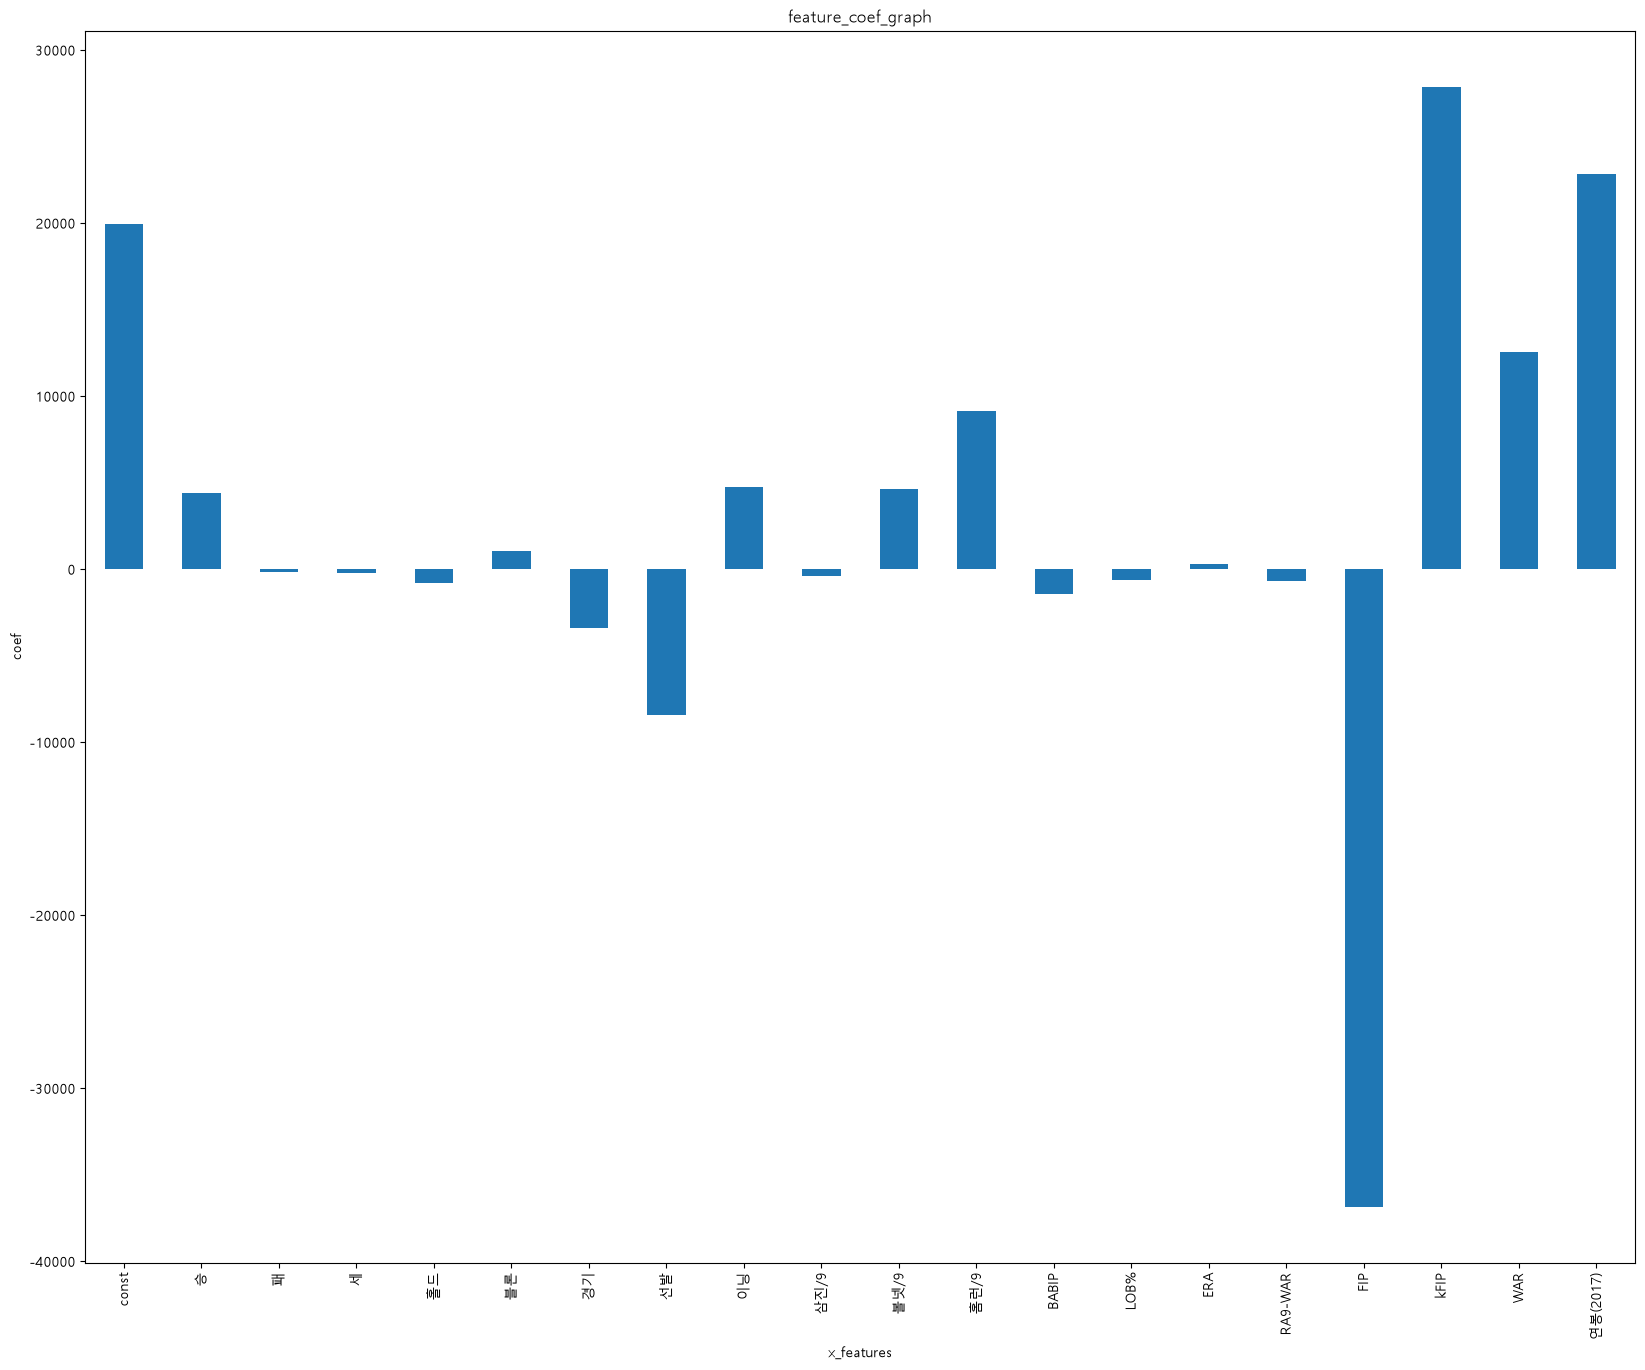

In [162]:
#결정하는 결과에 영향을 미치는 것을 파악
plt.rcParams['figure.figsize'] = [20, 16]

# 회귀 계수를 리스트로 반환합니다.
coefs = model.params.tolist()
coefs_series = pd.Series(coefs)

# 변수명을 리스트로 반환합니다.
x_labels = ['const'] + [
    '승', '패', '세', '홀드', '블론', '경기',
    '선발', '이닝', '삼진/9', '볼넷/9',
    '홈런/9', 'BABIP', 'LOB%', 'ERA',
    'RA9-WAR', 'FIP', 'kFIP', 'WAR',
    '연봉(2017)'
]

# 회귀 계수를 출력합니다.
ax = coefs_series.plot(kind='bar')
ax.set_title('feature_coef_graph')
ax.set_xlabel('x_features')
ax.set_ylabel('coef')
ax.set_xticklabels(x_labels)

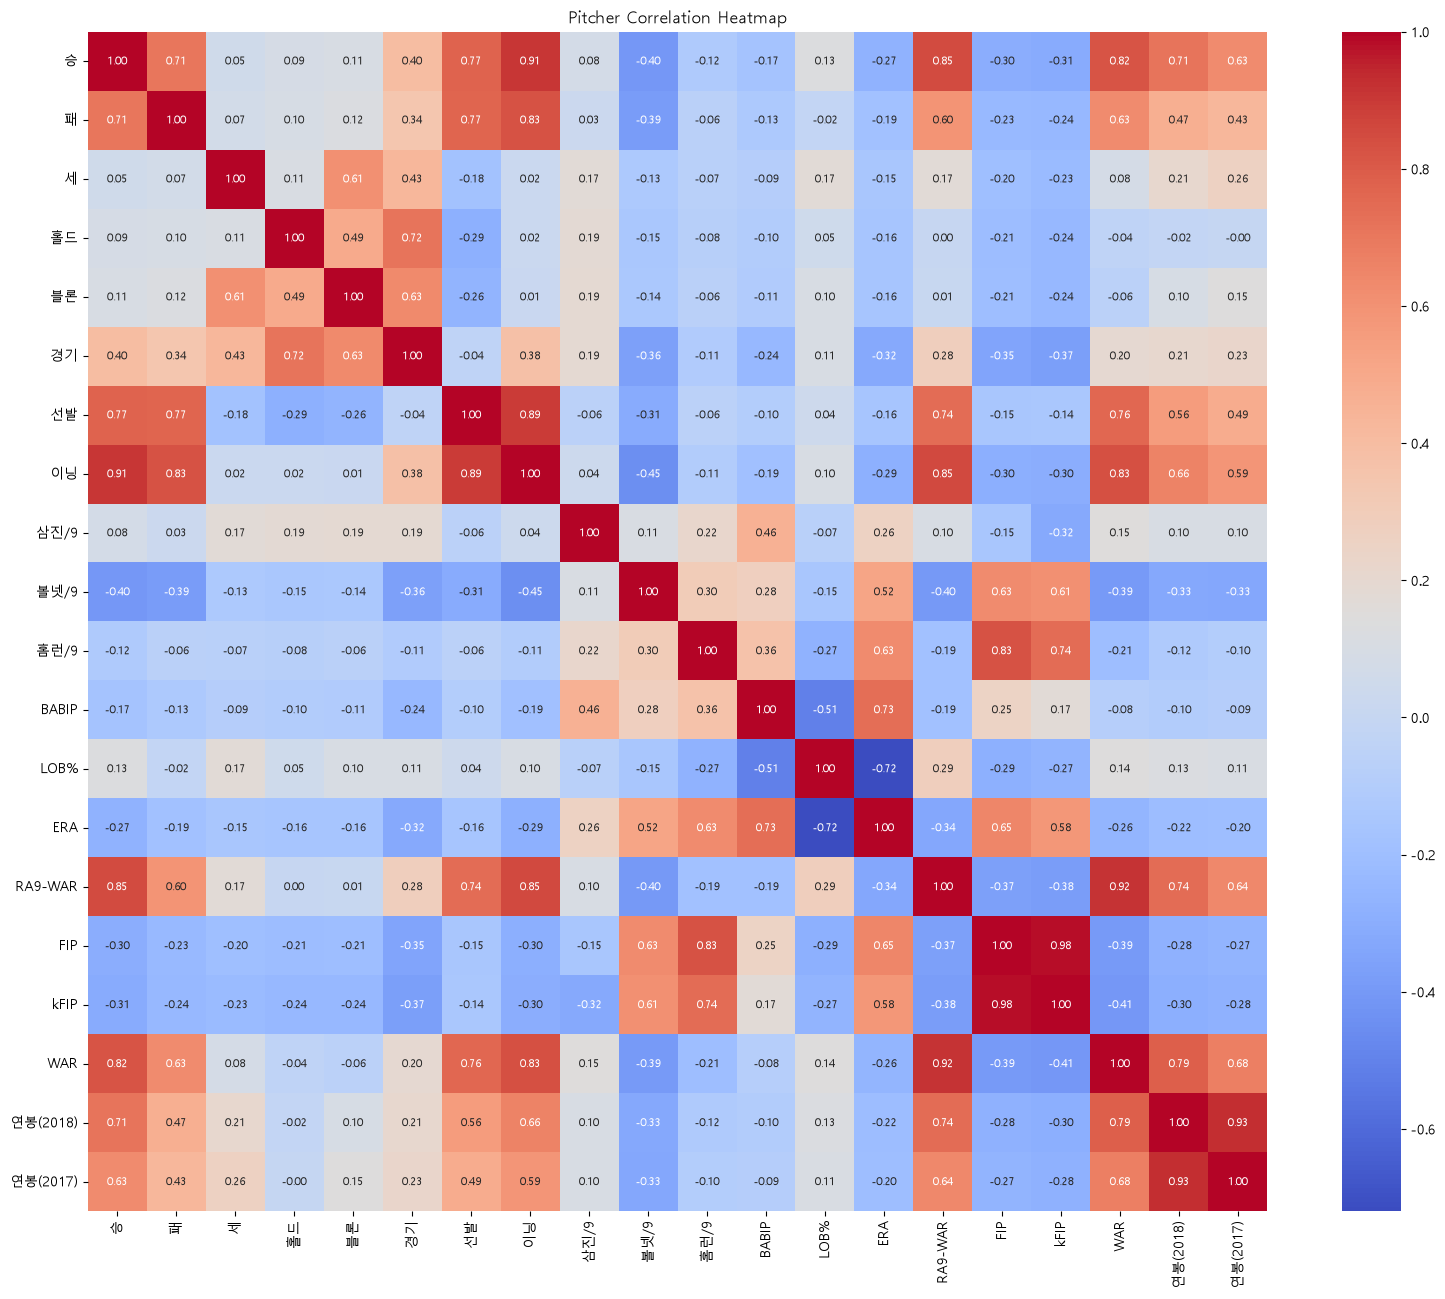

In [163]:

import matplotlib.pyplot as plt
import seaborn as sns

# 1. 숫자형 컬럼만 선택
numeric_df = df.select_dtypes(include='number')

# 2. 피처 간 상관계수 계산
corr = numeric_df.corr(method='pearson')

# 3. 컬럼 이름 가져오기
show_cols = corr.columns.tolist()

# 4. 그래프 크기 설정
plt.figure(figsize=(16, 13))

# 5. 상관관계 히트맵
sns.heatmap(
    corr,
    cmap='coolwarm',
    annot=True,
    square=True,
    fmt='.2f',
    annot_kws={'size': 8},
    xticklabels=show_cols,
    yticklabels=show_cols
)

# 6. 그래프 설정
plt.title('Pitcher Correlation Heatmap')
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


In [164]:

import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# VIF 결과 저장
vif = pd.DataFrame()

# 각 컬럼의 VIF 계산
vif["VIF Factor"] = [
    variance_inflation_factor(data, i)
    for i in range(data.shape[1])
]

# 컬럼 이름 가져오기
vif["features"] = df.drop(
    columns=['선수명', '팀명', '연봉(2018)']
).columns

# 결과 출력
vif.round(1)


,VIF Factor,features
0,7.7,승
1,5.3,패
2,3.0,세
3,3.6,홀드
4,2.8,블론
5,14.2,경기
6,36.2,선발
7,60.3,이닝
8,78.7,삼진/9
9,50.7,볼넷/9


In [165]:
# 피처를 재선정합니다.
data = df[['FIP', 'WAR', '볼넷/9', '삼진/9', '연봉(2017)']]
label = df['연봉(2018)']

In [166]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [167]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [168]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료') 

완료


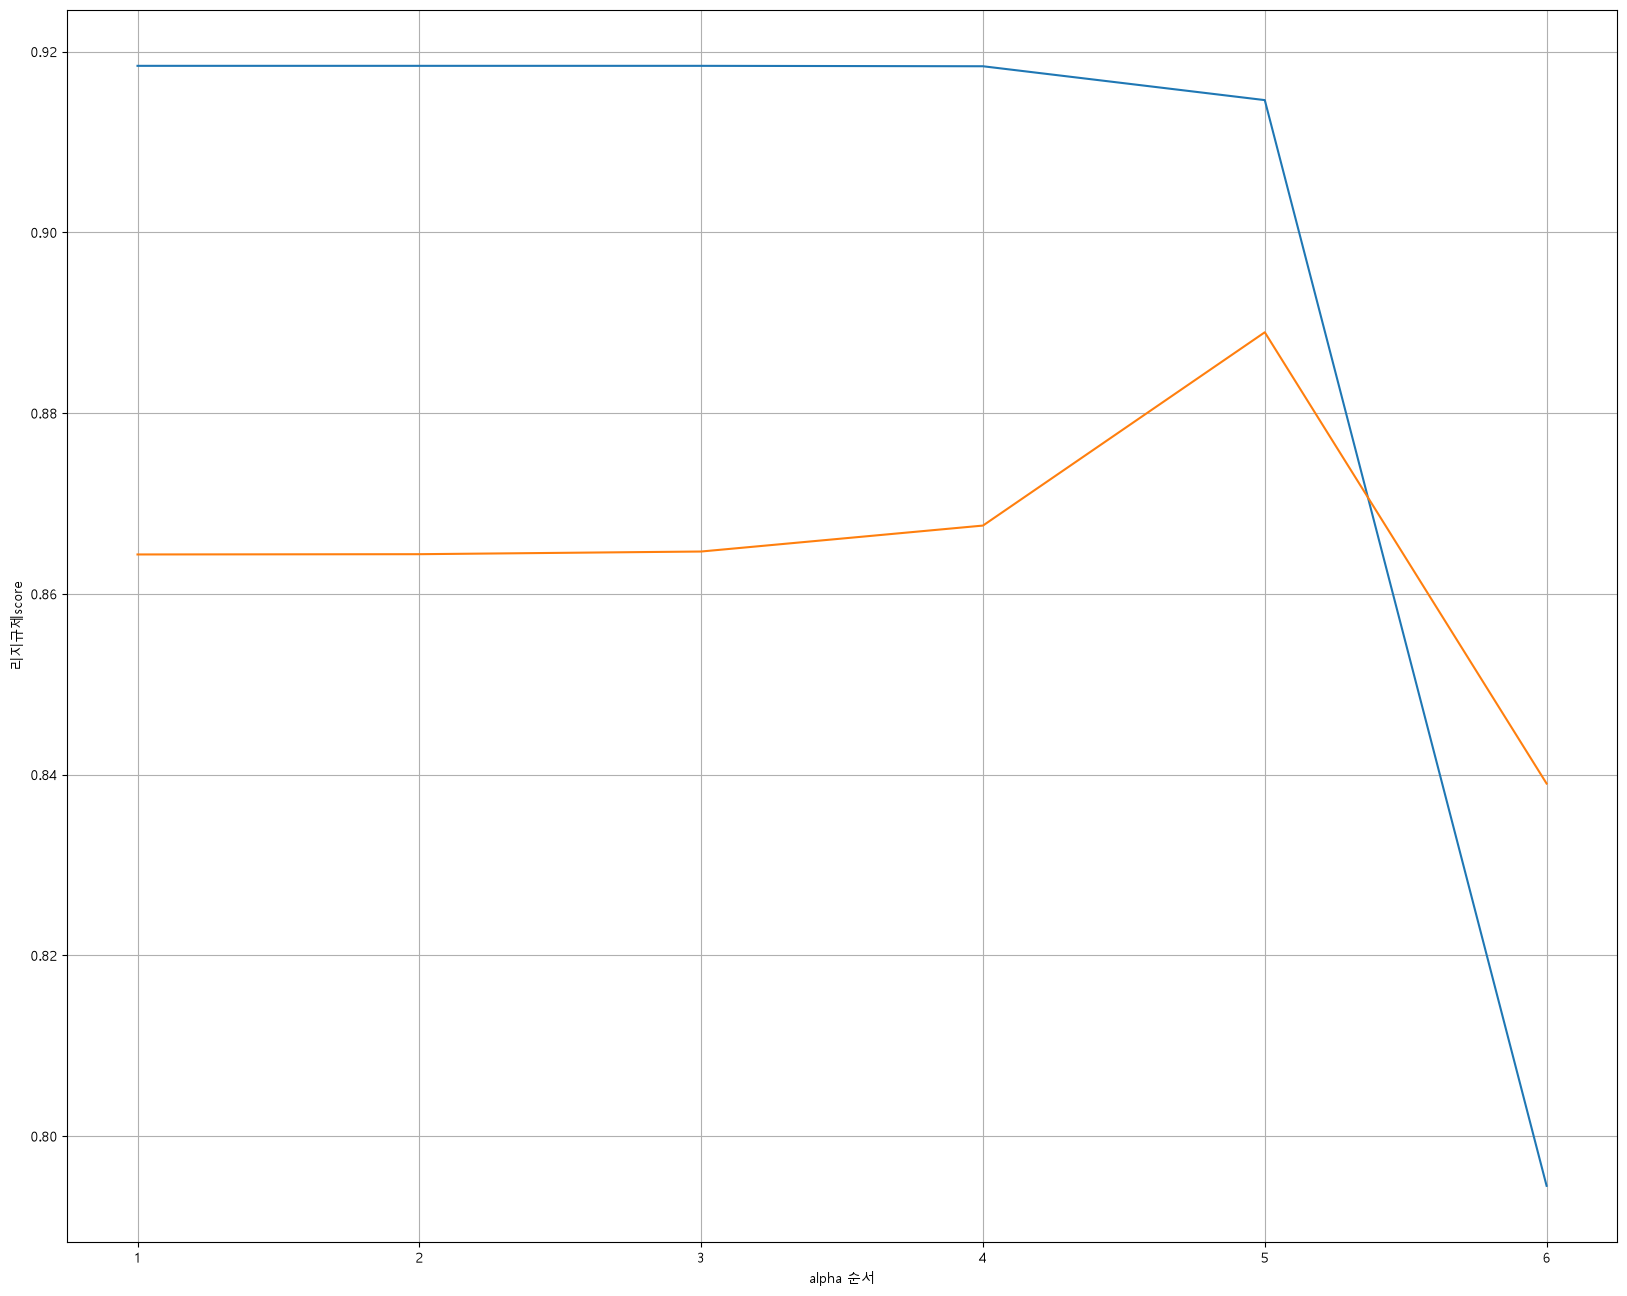

In [169]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
# plt.rc('font', family='Malgun Gothic')
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.grid()
plt.show()

In [170]:
ridge = Ridge(alpha=10)
model = ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9146248487099662
test 정확도 :  0.8889358101739498
